Q2. Perform image zooming and shrinking using different interpolation techniques:

    a. Nearest-neighbor interpolation
    b. Bilinear interpolation
    c. Bicubic interpolation
    
    Perform:
    •   2× zooming
    •   4× zooming
    •   1/2 shrinking
    •   1/4 shrinking

Compare the visual quality of the resulting images.

In [ ]:
# modules import and path loading
import os

import cv2
import matplotlib.pyplot as plt

image_path = "input.jpg"
if not os.path.isfile(image_path):
    image_path = os.path.join("..", "input.jpg")

if not os.path.isfile(image_path):
    raise FileNotFoundError(
        "Could not find input.jpg in the current folder or its parent folder."
    )

image_bgr = cv2.imread(image_path)
if image_bgr is None:
    raise ValueError(f"OpenCV could not read the image file: {os.path.abspath(image_path)}")

image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
height, width = image.shape[:2]


def show_results(method_name, transformed_images):
    labels = ["Original", "2x zoom", "4x zoom", "1/2 shrink", "1/4 shrink"]
    images = [image] + transformed_images
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    for axis, label, result in zip(axes.flat, labels, images):
        axis.imshow(result)
        axis.set_title(label)
        axis.axis("off")
    axes.flat[-1].axis("off")
    fig.suptitle(f"{method_name} interpolation", fontsize=16)
    plt.tight_layout()
    plt.show()

print(f"Loaded {os.path.abspath(image_path)} ({width} x {height})")
# print("cell working")

Loaded c:\Programming file\VS coder file\Python programs\Image processing\input.jpg (2550 x 3300)


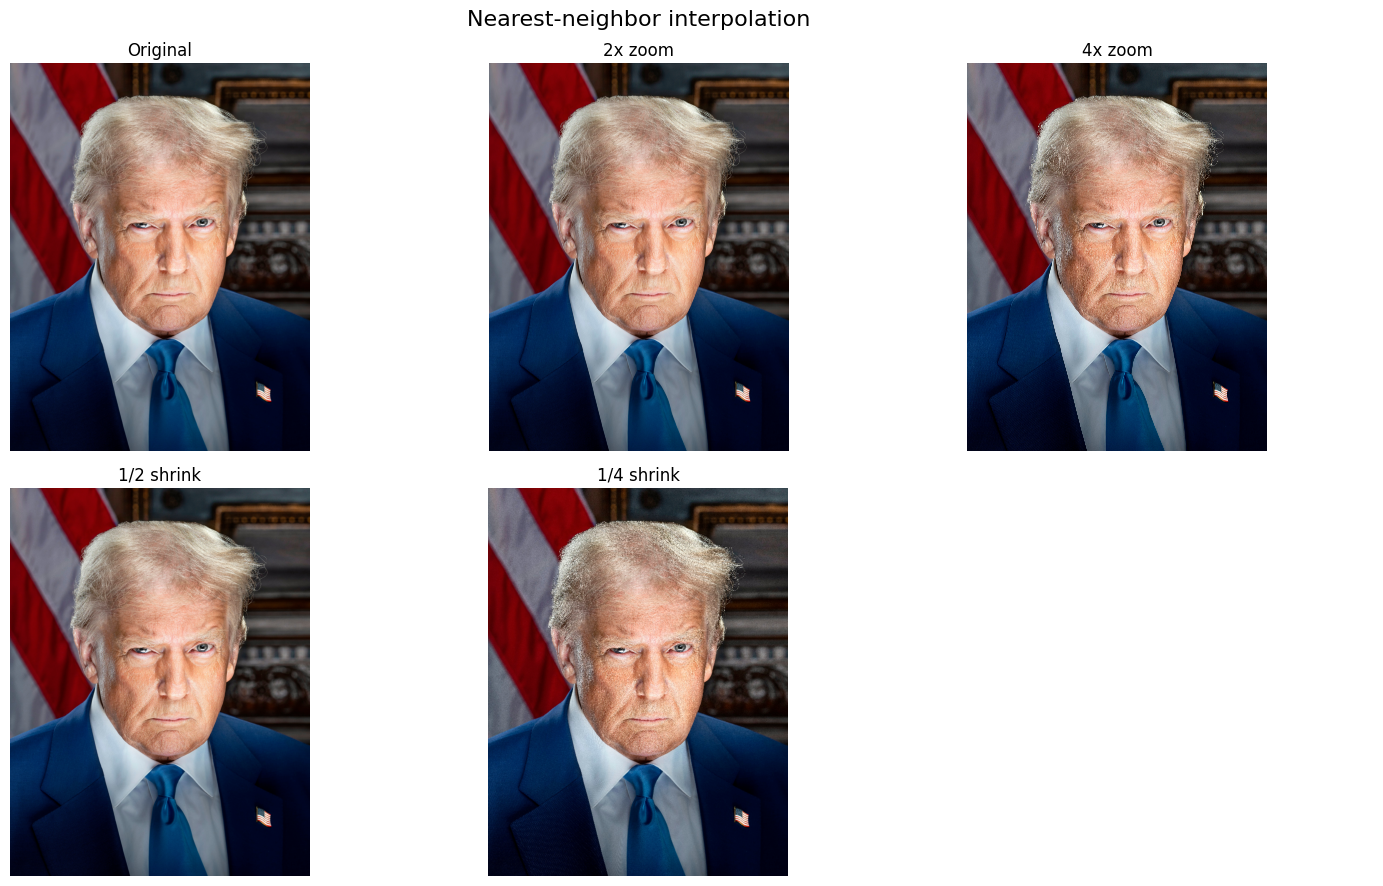

In [2]:
# a. Nearest-neighbor interpolation
nearest_2x = cv2.resize(image, None, fx=2, fy=2, interpolation=cv2.INTER_NEAREST)
nearest_4x = cv2.resize(image, None, fx=4, fy=4, interpolation=cv2.INTER_NEAREST)
nearest_half = cv2.resize(image, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_NEAREST)
nearest_quarter = cv2.resize(image, None, fx=0.25, fy=0.25, interpolation=cv2.INTER_NEAREST)
show_results("Nearest-neighbor", [nearest_2x, nearest_4x, nearest_half, nearest_quarter])

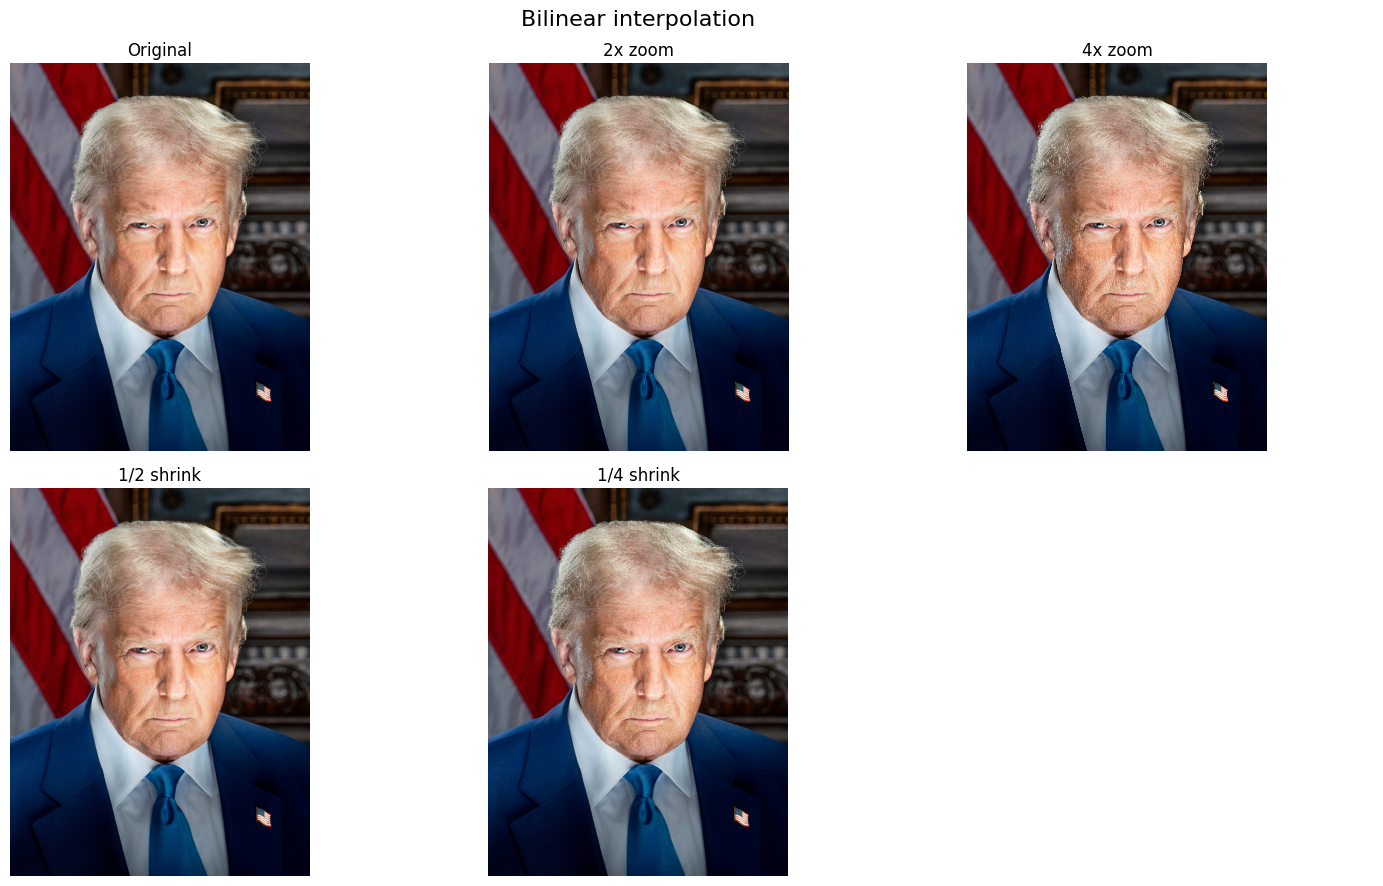

In [3]:
# b. Bilinear interpolation (OpenCV's INTER_LINEAR)
bilinear_2x = cv2.resize(image, None, fx=2, fy=2, interpolation=cv2.INTER_LINEAR)
bilinear_4x = cv2.resize(image, None, fx=4, fy=4, interpolation=cv2.INTER_LINEAR)
bilinear_half = cv2.resize(image, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_LINEAR)
bilinear_quarter = cv2.resize(image, None, fx=0.25, fy=0.25, interpolation=cv2.INTER_LINEAR)
show_results("Bilinear", [bilinear_2x, bilinear_4x, bilinear_half, bilinear_quarter])

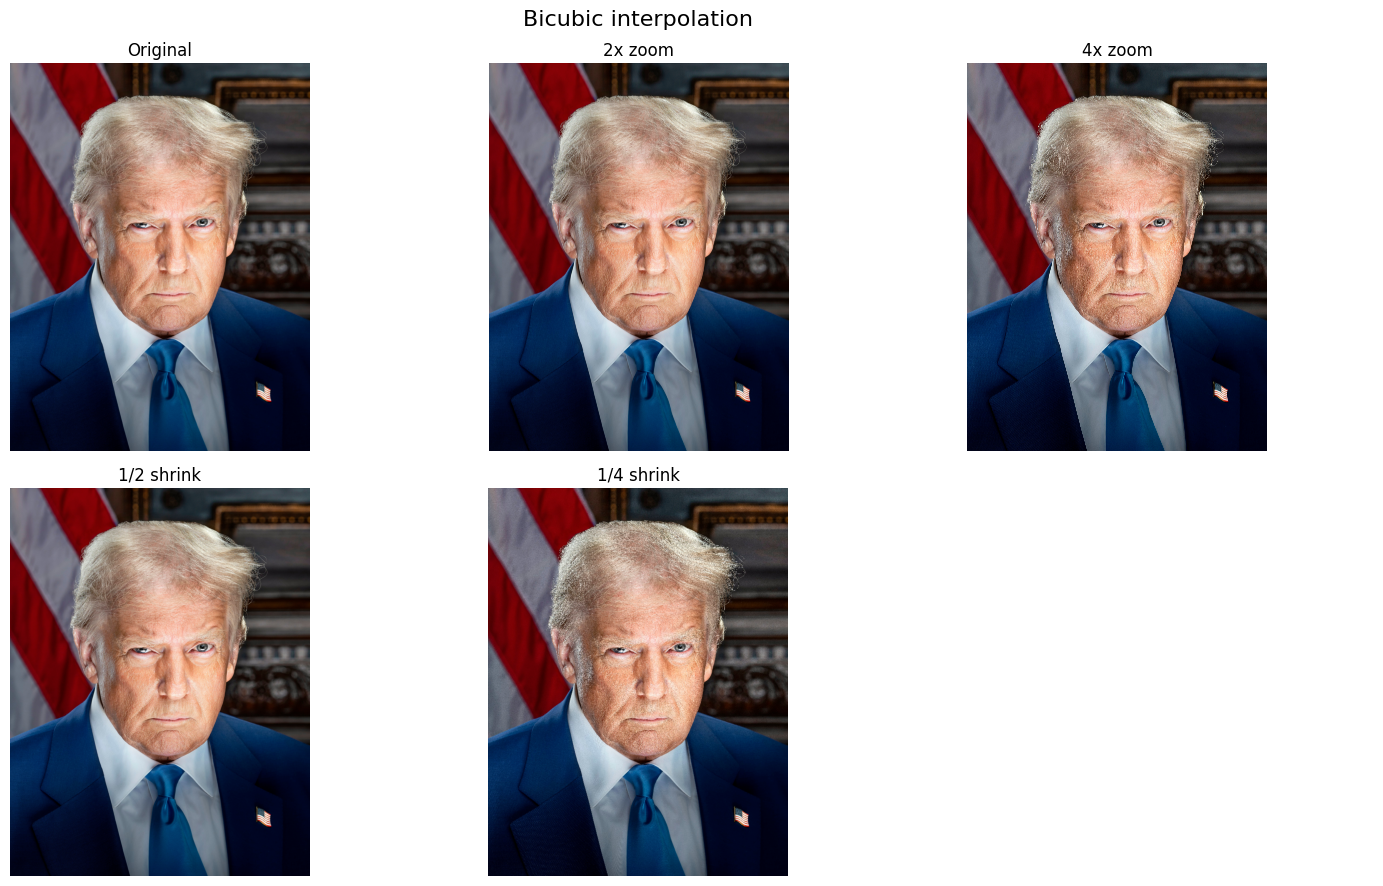

In [4]:
# c. Bicubic interpolation (OpenCV's INTER_CUBIC)
bicubic_2x = cv2.resize(image, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
bicubic_4x = cv2.resize(image, None, fx=4, fy=4, interpolation=cv2.INTER_CUBIC)
bicubic_half = cv2.resize(image, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_CUBIC)
bicubic_quarter = cv2.resize(image, None, fx=0.25, fy=0.25, interpolation=cv2.INTER_CUBIC)
show_results("Bicubic", [bicubic_2x, bicubic_4x, bicubic_half, bicubic_quarter])

### Visual comparison

- **Nearest-neighbor** preserves original pixel values but often looks blocky when zoomed and jagged when reduced.
- **Bilinear** blends nearby pixels, so it usually looks smoother but can appear softer.
- **Bicubic** uses a wider neighborhood and often gives smoother, more detailed-looking results, though it can introduce slight overshoot around sharp edges.

Compare each scale factor across the three figures. Zooming creates interpolated pixels, it does not restore detail that was absent from the original.